# **Identitas**

Nama: Putri Sofiyatus Salwa

Kelas: 2024A

NIM: 24031554112

## **1.2 Mempelajari Penggunaan Driver Neo4j**

In [6]:
%pip install --upgrade --force-reinstall "neo4j==5.28.8"

  Using cached neo4j-5.28.8-py3-none-any.whl.metadata (5.9 kB)
  Using cached pytz-2026.5-py2.py3-none-any.whl.metadata (22 kB)
Using cached neo4j-5.28.8-py3-none-any.whl (314 kB)
Using cached pytz-2026.5-py2.py3-none-any.whl (506 kB)

  Attempting uninstall: pytz

    Found existing installation: pytz 2026.5

    Uninstalling pytz-2026.5:

      Successfully uninstalled pytz-2026.5

   ---------------------------------------- 0/2 [pytz]
   ---------------------------------------- 0/2 [pytz]
   ---------------------------------------- 0/2 [pytz]
  Attempting uninstall: neo4j
   ---------------------------------------- 0/2 [pytz]
    Found existing installation: neo4j 5.28.8
   ---------------------------------------- 0/2 [pytz]
   -------------------- ------------------- 1/2 [neo4j]
    Uninstalling neo4j-5.28.8:
   -------------------- ------------------- 1/2 [neo4j]
      Successfully uninstalled neo4j-5.28.8
   -------------------- ------------------- 1/2 [neo4j]
   ----------------

In [1]:
import neo4j
from neo4j import GraphDatabase, RoutingControl

print("Versi Neo4j:", neo4j.__version__)
print("RoutingControl berhasil diimpor!")

Versi Neo4j: 5.28.8
RoutingControl berhasil diimpor!


In [2]:
URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "Salwauts1806")

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()
    print("Koneksi ke Neo4j berhasil!")

Koneksi ke Neo4j berhasil!


In [3]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        """
        MERGE (a:Person {name: $name})
        MERGE (friend:Person {name: $friend_name})
        MERGE (a)-[:KNOWS]->(friend)
        """,
        name=name,
        friend_name=friend_name,
        database_="neo4j",
    )


def print_friends(driver, name):
    records, summary, keys = driver.execute_query(
        """
        MATCH (a:Person)-[:KNOWS]->(friend)
        WHERE a.name = $name
        RETURN friend.name AS friend
        ORDER BY friend.name
        """,
        name=name,
        database_="neo4j",
        routing_=RoutingControl.READ,
    )

    for record in records:
        print(record["friend"])

In [ ]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")

    print("Teman Arthur:")
    print_friends(driver, "Arthur")

Teman Arthur:


Received notification from DBMS server: {severity: WARNING} {code: Neo.ClientNotification.Statement.FeatureDeprecationWarning} {category: DEPRECATION} {title: This feature is deprecated and will be removed in future versions.} {description: The subclause expression `friend.name` contains an ambiguous reference to variable `friend` and is deprecated. It is replaced by referencing the projection item expression by an alias or using the `GROUP BY` clause.} {position: line: 5, column: 24, offset: 134} for query: '\n        MATCH (a:Person)-[:KNOWS]->(friend)\n        WHERE a.name = $name\n        RETURN friend.name AS friend\n        ORDER BY friend.name\n        '


Guinevere
Lancelot
Merlin


### **Pertanyaan Pendahuluan**

1. Apa nama database yang digunakan pada tutorial ini?

Database yang digunakan adalah neo4j, sesuai dengan parameter database_="neo4j" pada fungsi driver.execute_query()

2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database lain dalam 1 instance?

Database Neo4j dapat diakses menggunakan bahasa query Cypher. Seperti CREATE untuk membuat node atau relasi, MATCH untuk mencari pola pada graf, MERGE untuk mencocokkan atau membuat data jika belum ada, serta SET untuk memperbarui properti

3. Apa jenis graf pertemanan yang telah dibuat di sini?

Graf pertemanan berarah (directed graph), karena relasi KNOWS dibuat dari node Arthur menuju node teman-temannya. Arah relasi ditunjukkan oleh tanda panah pada pola Cypher.


## **1.3 Melakukan Proses Impor Data dari RetailRocker ke Database Neo4j**

In [6]:
%pip install pandas

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---- ----------------------------------- 1.3/11.3 MB 8.4 MB/s eta 0:00:02
   ----- ---------------------------------- 1.6/11.3 MB 8.4 MB/s eta 0:00:02
   ------ --------------------------------- 1.8/11.3 MB 3.9 MB/s eta 0:00:03
   ------- -------------------------------- 2.1/11.3 MB 3.0 MB/s eta 0:00:04
   -------- ------------------------------- 2.4/11.3 MB 2.6 MB/s eta 0:00:04
   --------- ------------------------------ 2.6/11.3 MB 2.4 MB/s eta 0:00:04
   ----------- ---------------------------- 3.1/11.3 MB 2.1 MB/s eta 0:00:04
   ----------- ---------------------------- 3.1/11.3 MB 2.1 MB/s eta 0:00:04
   ------------ --------------------------- 3.4/11.3 MB 1.9 MB/s eta 0:00:05
   ------------- -------------------------- 3.9/11.3 MB 1.8 MB/s eta 0:00:05
   ------------- -------------------------- 3.9/11.3 MB 1.8 MB/s eta 0:00:05
   -------------- ------------------------- 4.2/11.3 MB 1.7 MB/s eta 0:00:05
   ---

**Mengecek informasi terkait data**

In [12]:
import pandas as pd
from pathlib import Path

DATA_PATH = Path("data/events.csv")

events = pd.read_csv(DATA_PATH)

print("Ukuran dataset:", events.shape)
print("\nNama kolom:")
print(events.columns.tolist())

print("\nLima baris pertama:")
display(events.head())

print("\nInformasi dataset:")
events.info()

Ukuran dataset: (2756101, 5)

Nama kolom:
['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']

Lima baris pertama:


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN



Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          object 
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), object(1)
memory usage: 105.1+ MB


**Pembuatan Session Neo4J**

In [8]:
from neo4j import GraphDatabase

uri = "neo4j://127.0.0.1:7687"
user = "neo4j"
password = "Salwauts1806"

driver = GraphDatabase.driver(uri, auth=(user, password))
session = driver.session(database="system")

print("Session Neo4j berhasil dibuat!")

Session Neo4j berhasil dibuat!


**Pemeriksaan Keberadaan Berkas events.csv**

In [9]:
import os
import sys

csv_file_path = os.path.join("data", "events.csv")

if not os.path.exists(csv_file_path):
    print(f"Error! File '{csv_file_path}' tidak ditemukan!")
    sys.exit(1)

print(f"File ditemukan: {csv_file_path}")

File ditemukan: data\events.csv


**Pembuatan Koneksi**

In [11]:
try:
    driver.verify_connectivity()
    print("Koneksi ke Neo4j berhasil!")

    result = session.run("SHOW DATABASES")
    print("\nDatabase yang tersedia:")

    for record in result:
        print("-", record["name"])

except Exception as e:
    print("Gagal terhubung ke database:", e)

Koneksi ke Neo4j berhasil!

Database yang tersedia:
- neo4j
- system


**Membuat fungsi create constraint. Bertujuan agar setiap ID hanya mengidentifikasi satu node dalam label terkait**

In [17]:
def create_constraints(session):
    session.run("""
        CREATE CONSTRAINT visitor_id IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorid IS UNIQUE
    """)

    session.run("""
        CREATE CONSTRAINT item_id IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.itemid IS UNIQUE
    """)

    print("Constraint Visitor dan Item berhasil dibuat.")

**Import Data dengan Mekanisme Batch**

In [18]:
def import_batch(tx, records):
    query = """
    UNWIND $rows AS row

    MERGE (v:Visitor {visitorid: row.visitorid})
    MERGE (i:Item {itemid: row.itemid})

    FOREACH (_ IN CASE WHEN row.event = 'view' THEN [1] ELSE [] END |
        MERGE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
    )

    FOREACH (_ IN CASE WHEN row.event = 'addtocart' THEN [1] ELSE [] END |
        MERGE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
    )

    FOREACH (_ IN CASE WHEN row.event = 'transaction' THEN [1] ELSE [] END |
        MERGE (v)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionId: row.transactionid
        }]->(i)
    )
    """

    tx.run(query, rows=records)

In [15]:
%pip install tqdm

Note: you may need to restart the kernel to use updated packages.


In [20]:
from tqdm.auto import tqdm
import pandas as pd

batch_size = 10000

with open(csv_file_path, "r", encoding="utf-8") as f:
    total_rows = sum(1 for _ in f) - 1

total_chunks = (total_rows // batch_size) + 1

with driver.session(database="neo4j") as session:
    create_constraints(session)

    print(f"Membaca file data dari: {csv_file_path}")
    print(f"Total baris data: {total_rows:,}")
    print(f"Total batch: {total_chunks}")

    chunks = pd.read_csv(
        csv_file_path,
        chunksize=batch_size
    )

    print("Memulai proses impor data ke Neo4j...")

    for chunk in tqdm(
        chunks,
        total=total_chunks,
        desc="Mengimpor Batch Data"
    ):
        chunk["transactionid"] = (
            chunk["transactionid"].fillna("").astype(str)
        )

        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

driver.close()
print("Proses impor selesai.")

Constraint Visitor dan Item berhasil dibuat.
Membaca file data dari: data\events.csv
Total baris data: 2,756,101
Total batch: 276
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 276/276 [07:23<00:00,  1.61s/it]

Proses impor selesai.


In [35]:

from neo4j import GraphDatabase

uri = "neo4j://127.0.0.1:7687"
user = "neo4j"
password = "Salwauts1806"

driver = GraphDatabase.driver(
    uri,
    auth=(user, password)
)

driver.verify_connectivity()
print("Koneksi Neo4j berhasil!")


Koneksi Neo4j berhasil!


**Memeriksa Jumlah Relasi**

In [21]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        result = session.run("""
            MATCH (v:Visitor)
            RETURN count(v) AS total_visitor
        """)
        print("Total Visitor:", result.single()["total_visitor"])

        result = session.run("""
            MATCH (i:Item)
            RETURN count(i) AS total_item
        """)
        print("Total Item:", result.single()["total_item"])

        result = session.run("""
            MATCH ()-[r]->()
            RETURN count(r) AS total_relationship
        """)
        print("Total Relationship:", result.single()["total_relationship"])

Total Visitor: 1407580
Total Item: 235061
Total Relationship: 2755644


In [22]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    with driver.session(database="neo4j") as session:
        result = session.run("""
            MATCH ()-[r]->()
            RETURN type(r) AS jenis_relasi, count(r) AS jumlah
            ORDER BY jumlah DESC
        """)

        for record in result:
            print(f"{record['jenis_relasi']}: {record['jumlah']}")

VIEWED: 2664218
ADDED_TO_CART: 68966
BOUGHT: 22457
KNOWS: 3


In [23]:
import pandas as pd

events = pd.read_csv("data/events.csv")

print("Total baris:", len(events))
print(
    "Duplikat berdasarkan visitorid, itemid, timestamp, event:",
    events.duplicated(
        subset=["visitorid", "itemid", "timestamp", "event"]
    ).sum()
)

Total baris: 2756101
Duplikat berdasarkan visitorid, itemid, timestamp, event: 460


### **Verifikasi Hasil Impor Dataset**

Proses impor dataset RetailRocket berhasil dilakukan menggunakan mekanisme batch dengan ukuran 10.000 baris per batch. Sebanyak 2.756.101 baris data diproses dalam 276 batch.

Hasil verifikasi pada database Neo4j menunjukkan 1.407.580 node Visitor, 235.061 node Item, dan 2.755.644 relasi secara keseluruhan. Dari jumlah tersebut, 2.755.641 relasi berasal dari dataset RetailRocket, sedangkan 3 relasi KNOWS berasal dari percobaan tutorial sebelumnya.

Pemeriksaan dataset menemukan 460 baris duplikat berdasarkan kombinasi visitorid, itemid, timestamp, dan event. Temuan ini konsisten dengan selisih jumlah baris dan jumlah relasi RetailRocket yang tersimpan, karena proses impor menggunakan MERGE untuk membentuk relasi.

# **2. SOAL UTS**

## **2.1 Wrangling dan EDA**

### **Nomor 1:** 
**Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yang dipilih per individu tidak boleh sama dalam 1 kelas**

### **Nomor 2:**
**Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv**

**Penentuan Periode Training dan Testing**

In [4]:
import os
import pandas as pd

events = pd.read_csv("data/events.csv")

tanggal_mulai = pd.Timestamp("2015-05-03").timestamp() * 1000
tanggal_batas = pd.Timestamp("2015-08-11").timestamp() * 1000
tanggal_akhir = pd.Timestamp("2015-09-19").timestamp() * 1000

training = events[
    (events["timestamp"] >= tanggal_mulai) &
    (events["timestamp"] < tanggal_batas)
].copy()

testing = events[
    (events["timestamp"] >= tanggal_batas) &
    (events["timestamp"] < tanggal_akhir)
].copy()

os.makedirs("data/periode", exist_ok=True)
training.to_csv("data/periode/P1_training.csv", index=False)
testing.to_csv("data/periode/P2_testing.csv", index=False)

print("P1 Training:", training.shape)
print("P2 Testing:", testing.shape)
print("Total baris:", len(training) + len(testing))

P1 Training: (2076691, 5)
P2 Testing: (679410, 5)
Total baris: 2756101


In [5]:
import pandas as pd

training = pd.read_csv("data/periode/P1_training.csv")
testing = pd.read_csv("data/periode/P2_testing.csv")

print("Jumlah baris P1:", len(training))
print("Jumlah baris P2:", len(testing))

print(
    "Periode P1:",
    pd.to_datetime(training["timestamp"], unit="ms").min(),
    "sampai",
    pd.to_datetime(training["timestamp"], unit="ms").max()
)

print(
    "Periode P2:",
    pd.to_datetime(testing["timestamp"], unit="ms").min(),
    "sampai",
    pd.to_datetime(testing["timestamp"], unit="ms").max()
)

print(
    "Total baris:",
    len(training) + len(testing)
)


Jumlah baris P1: 2076691
Jumlah baris P2: 679410
Periode P1: 2015-05-03 03:00:04.384000 sampai 2015-08-10 23:59:58.662000
Periode P2: 2015-08-11 00:00:00.692000 sampai 2015-09-18 02:59:47.788000
Total baris: 2756101


**Hasil dan Interpretasi Nomor 1 dan 2**

Dataset RetailRocket dibagi menjadi dua periode waktu berdasarkan kolom timestamp. Periode P1 (training) mencakup 3 Mei hingga 10 Agustus 2015, sedangkan periode P2 (testing) mencakup 11 Agustus hingga 18 September 2015.

Pada tahap ini, data difilter berdasarkan rentang waktu yang telah ditentukan dan disimpan dalam dua file CSV, yaitu P1_training.csv dan P2_testing.csv di folder data/periode.

Hasil pemfilteran menghasilkan 2.076.691 baris data pada P1 dan 679.410 baris data pada P2, dengan total 2.756.101 baris. P1 digunakan untuk membangun representasi interaksi dan model rekomendasi, sedangkan P2 digunakan untuk mengevaluasi rekomendasi menggunakan data pada periode berikutnya.

Berdasarkan hasil verifikasi, rentang waktu kedua periode tidak tumpang tindih. Dengan demikian, data training dan testing dipisahkan berdasarkan waktu sehingga interaksi pada periode testing terjadi setelah periode training.

### **Nomor 3:**
**Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!**


In [7]:
import pandas as pd

start_p1_ms = int(
    pd.Timestamp("2015-05-03", tz="UTC").timestamp() * 1000
)
end_p1_ms = int(
    pd.Timestamp("2015-08-11", tz="UTC").timestamp() * 1000
)

query_komposisi = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= $start_ms
  AND r.timestamp < $end_ms
  AND type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN
    count(DISTINCT v) AS jumlah_visitor,
    count(DISTINCT i) AS jumlah_item,
    count(r) AS total_relasi,
    sum(CASE WHEN type(r) = 'VIEWED' THEN 1 ELSE 0 END)
        AS jumlah_viewed,
    sum(CASE WHEN type(r) = 'ADDED_TO_CART' THEN 1 ELSE 0 END)
        AS jumlah_added_to_cart,
    sum(CASE WHEN type(r) = 'BOUGHT' THEN 1 ELSE 0 END)
        AS jumlah_bought
"""

with driver.session(database="neo4j") as session:
    record = session.run(
        query_komposisi,
        start_ms=start_p1_ms,
        end_ms=end_p1_ms
    ).single()

komposisi = pd.DataFrame({
    "Jenis Komponen": [
        "Simpul Visitor",
        "Simpul Item",
        "Relasi VIEWED",
        "Relasi ADDED_TO_CART",
        "Relasi BOUGHT",
        "Total Relasi"
    ],
    "Jumlah": [
        record["jumlah_visitor"],
        record["jumlah_item"],
        record["jumlah_viewed"],
        record["jumlah_added_to_cart"],
        record["jumlah_bought"],
        record["total_relasi"]
    ]
})

print("KOMPOSISI SUBGRAPH P1")
display(komposisi)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_19168\2086328819.py:27: DeprecationWarning: Using a driver after it has been closed is deprecated. Future versions of the driver will raise an error.
  with driver.session(database="neo4j") as session:


KOMPOSISI SUBGRAPH P1


,Jenis Komponen,Jumlah
0,Simpul Visitor,1055676
1,Simpul Item,207371
2,Relasi VIEWED,2008139
3,Relasi ADDED_TO_CART,51383
4,Relasi BOUGHT,16842
5,Total Relasi,2076364


**Hasil dan Interpretasi Komposisi Subgraph**

Subgraph pada periode training P1 terdiri atas dua jenis simpul, yaitu Visitor dan Item. Visitor merepresentasikan pengguna yang berinteraksi dengan produk, sedangkan Item merepresentasikan produk yang menjadi objek interaksi.

Hasil query menunjukkan terdapat 1.055.676 simpul Visitor unik dan 207.371 simpul Item unik. Kedua jenis simpul tersebut terhubung melalui 2.076.364 relasi, yang terdiri atas 2.008.139 relasi VIEWED, 51.383 relasi ADDED_TO_CART, dan 16.842 relasi BOUGHT.

Relasi VIEWED merupakan jenis relasi yang paling dominan. Hal ini menunjukkan bahwa aktivitas melihat produk lebih banyak ditemukan dibandingkan aktivitas menambahkan produk ke keranjang maupun melakukan pembelian selama periode P1.

**Penjelasan Query Cypher**

Query diawali dengan MATCH (v:Visitor)-[r]->(i:Item) untuk mencari pola graf berupa simpul Visitor yang terhubung dengan simpul Item melalui relasi. Variabel v mewakili simpul Visitor, i mewakili simpul Item, dan r mewakili relasi di antara keduanya.

Klausa WHERE digunakan untuk membatasi data berdasarkan timestamp periode P1 dan memilih tiga jenis relasi, yaitu VIEWED, ADDED_TO_CART, dan BOUGHT. Parameter $start_ms dan $end_ms dikirimkan melalui Python API agar batas periode dapat ditentukan tanpa menuliskan nilai timestamp secara langsung di dalam query.

Fungsi count(DISTINCT v) menghitung jumlah Visitor unik, sedangkan count(DISTINCT i) menghitung jumlah Item unik. Fungsi count(r) menghitung jumlah relasi yang memenuhi kondisi. Sementara itu, sum(CASE WHEN ...) menghitung jumlah relasi berdasarkan jenisnya.

Query Cypher dijalankan melalui Python API Neo4j menggunakan session.run() dengan parameter batas waktu start_ms dan end_ms. Hasil query diambil menggunakan .single() karena query menghasilkan satu record agregat yang berisi jumlah simpul dan relasi. Nilai dari record tersebut kemudian diakses berdasarkan nama kolom hasil query dan disusun menjadi DataFrame pandas. Dengan cara ini, komposisi subgraph dapat diperoleh dari Neo4j dan ditampilkan dalam bentuk tabel yang mudah dibaca.

**Kesimpulan**

Subgraph RetailRocket pada periode P1 terdiri atas simpul Visitor dan Item yang dihubungkan oleh tiga jenis relasi interaksi. Relasi VIEWED mendominasi keseluruhan interaksi. Hasil ini menggambarkan komposisi graf berdasarkan data training dan diperoleh melalui query Cypher yang dijalankan menggunakan Python API Neo4j.


### **Nomor 4:**
**Lakukan Vektor Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)**

VSM digunakan untuk merepresentasikan setiap Visitor sebagai vektor berdasarkan interaksinya dengan Item. Setiap kolom merepresentasikan satu Item, sedangkan setiap baris merepresentasikan satu Visitor. Nilai matriks menunjukkan jumlah interaksi antara Visitor dan Item pada data training.


In [39]:
%pip install scipy

   ---------------------------------------- 0.0/41.3 MB ? eta -:--:--
    --------------------------------------- 0.5/41.3 MB 4.2 MB/s eta 0:00:10
    --------------------------------------- 0.8/41.3 MB 3.4 MB/s eta 0:00:13
    --------------------------------------- 0.8/41.3 MB 3.4 MB/s eta 0:00:13
   - -------------------------------------- 1.0/41.3 MB 1.4 MB/s eta 0:00:30
   -- ------------------------------------- 2.4/41.3 MB 2.3 MB/s eta 0:00:18
   -- ------------------------------------- 2.6/41.3 MB 2.2 MB/s eta 0:00:18
   -- ------------------------------------- 2.9/41.3 MB 2.1 MB/s eta 0:00:19
   --- ------------------------------------ 3.1/41.3 MB 2.0 MB/s eta 0:00:20
   --- ------------------------------------ 3.4/41.3 MB 1.8 MB/s eta 0:00:22
   --- ------------------------------------ 3.7/41.3 MB 1.8 MB/s eta 0:00:22
   --- ------------------------------------ 3.9/41.3 MB 1.8 MB/s eta 0:00:22
   ---- ----------------------------------- 4.2/41.3 MB 1.7 MB/s eta 0:00:23
   ---

In [8]:
import pandas as pd
import numpy as np
from scipy.sparse import coo_matrix

training = pd.read_csv("data/periode/P1_training.csv")

visitor_ids = pd.Index(training["visitorid"].unique())
item_ids = pd.Index(training["itemid"].unique())

visitor_index = visitor_ids.get_indexer(training["visitorid"])
item_index = item_ids.get_indexer(training["itemid"])

vsm_user = coo_matrix(
    (
        np.ones(len(training), dtype=np.int32),
        (visitor_index, item_index)
    ),
    shape=(len(visitor_ids), len(item_ids))
).tocsr()

vsm_user.sum_duplicates()

print("Jumlah Visitor:", len(visitor_ids))
print("Jumlah Item:", len(item_ids))
print("Shape VSM User:", vsm_user.shape)
print("Jumlah elemen non-zero:", vsm_user.nnz)
print("Tipe matriks:", type(vsm_user).__name__)


Jumlah Visitor: 1055676
Jumlah Item: 207371
Shape VSM User: (1055676, 207371)
Jumlah elemen non-zero: 1612019
Tipe matriks: csr_matrix


**Analisis VSM pada Simpul User**

VSM User dibentuk menggunakan data training P1 untuk merepresentasikan setiap Visitor (user) sebagai vektor interaksi terhadap Item. Matriks ini memiliki dua dimensi, yaitu baris dan kolom. Setiap baris merepresentasikan satu Visitor, sedangkan setiap kolom merepresentasikan satu Item.

Berdasarkan hasil perhitungan, matriks VSM User memiliki shape (1.055.676, 207.371), yang berarti terdapat 1.055.676 baris Visitor dan 207.371 kolom Item. Setiap elemen matriks menunjukkan jumlah interaksi antara Visitor dan Item yang bersangkutan.

Matriks disimpan menggunakan format sparse CSR (csr_matrix) untuk menghemat memori karena sebagian besar pasangan Visitor–Item tidak memiliki interaksi. Jumlah elemen non-zero adalah 1.612.019, yang menunjukkan jumlah elemen matriks yang bernilai bukan nol setelah nilai duplikat dijumlahkan.


**Plot Network untuk VSM User**

In [42]:
%pip install networkx matplotlib

   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ------------------------------------ --- 1.6/1.7 MB 10.5 MB/s eta 0:00:01
   ---------------------------------------- 1.7/1.7 MB 3.9 MB/s  0:00:00
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.2 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.2 MB 1.1 MB/s eta 0:00:07
   --- ------------------------------------ 0.8/8.2 MB 1.2 MB/s eta 0:00:07
   ------ --------------------------------- 1.3/8.2 MB 1.3 MB/s eta 0:00:06
   ------- -------------------------------- 1.6/8.2 MB 1.3 MB/s eta 0:00:06
   ------- -------------------------------- 1.6/8.2 MB 1.3 MB/s eta 0:00:06
   -------- ------------------------------- 1.8/8.2 MB 1.3 MB/s eta 0:00:06
   ----------- ---------------------------- 2.4/8.2 MB 1.3 MB/s eta 0:00:05
   ------------ --------------------------- 2.6/8.2 MB 1.3 MB/s eta 0:00:05
   -------------- -----------------

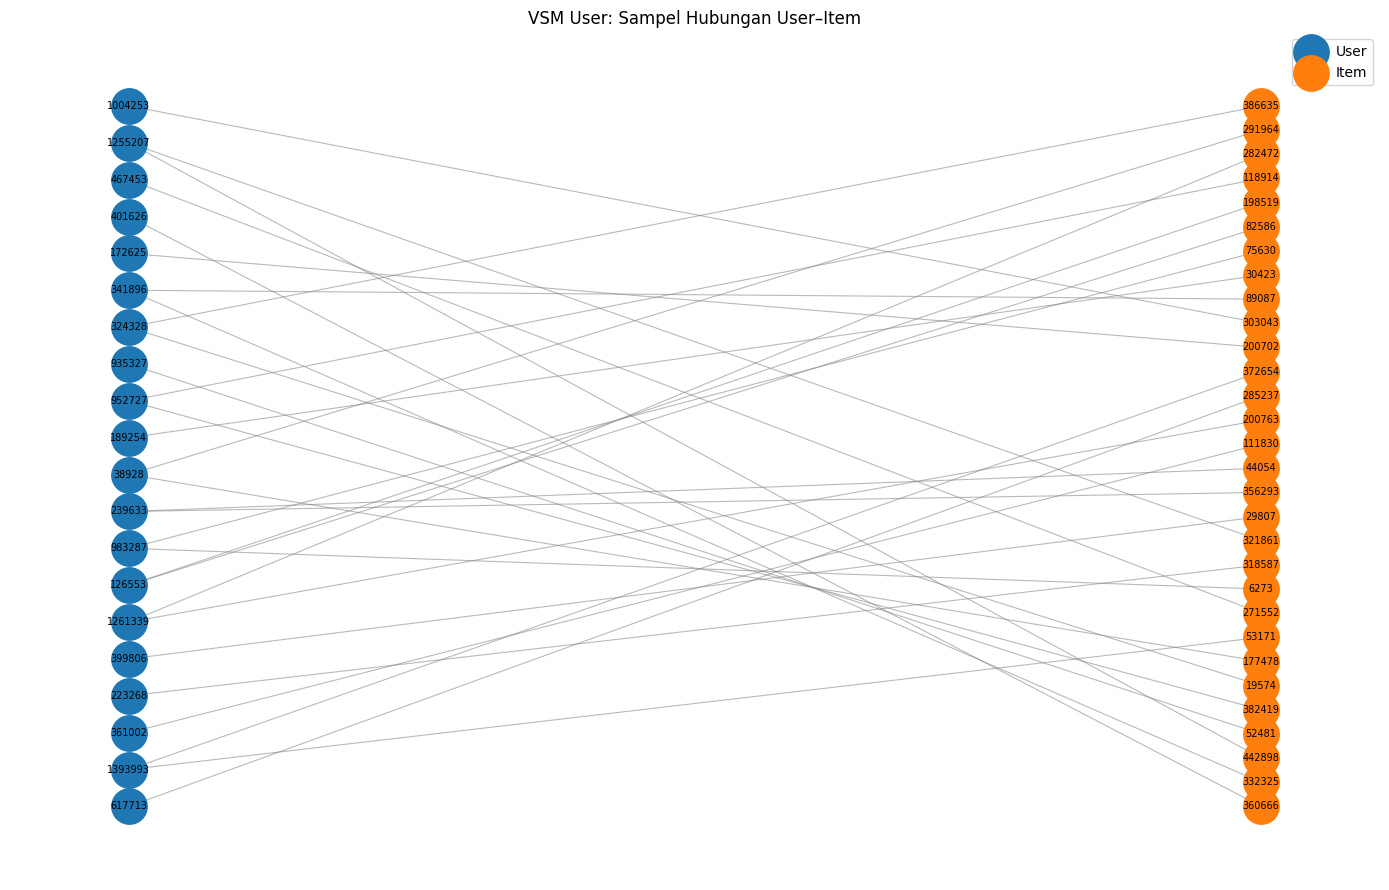

Jumlah simpul sampel: 50
Jumlah Visitor: 20
Jumlah Item: 30
Jumlah relasi sampel: 30


In [ ]:

import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

jumlah_item_per_visitor = np.diff(vsm_user.indptr)
kandidat_visitor = np.where(
    (jumlah_item_per_visitor >= 2) &
    (jumlah_item_per_visitor <= 6)
)[0]

rng = np.random.default_rng(42)
jumlah_visitor = min(25, len(kandidat_visitor))
pilihan_visitor = rng.choice(
    kandidat_visitor,
    size=jumlah_visitor,
    replace=False
)

kolom_item = set()
for idx in pilihan_visitor:
    kolom_item.update(vsm_user[idx].indices.tolist())

kolom_item = list(kolom_item)

frekuensi_item = np.asarray(
    vsm_user[pilihan_visitor, :][:, kolom_item].getnnz(axis=0)
).ravel()

urutan_item = np.argsort(frekuensi_item)[::-1][:30]
pilihan_item = [kolom_item[i] for i in urutan_item]

G_user = nx.Graph()

for idx in pilihan_visitor:
    G_user.add_node(
        f"V{visitor_ids[idx]}",
        jenis="Visitor"
    )

for idx in pilihan_item:
    G_user.add_node(
        f"I{item_ids[idx]}",
        jenis="Item"
    )

for vi in pilihan_visitor:
    for ii in pilihan_item:
        nilai = vsm_user[vi, ii]
        if nilai > 0:
            G_user.add_edge(
                f"V{visitor_ids[vi]}",
                f"I{item_ids[ii]}",
                weight=int(nilai)
            )

G_user.remove_nodes_from(list(nx.isolates(G_user)))

visitor_nodes = [
    n for n, d in G_user.nodes(data=True)
    if d["jenis"] == "Visitor"
]

pos = nx.bipartite_layout(
    G_user,
    visitor_nodes,
    align="vertical"
)

plt.figure(figsize=(14, 9))

nx.draw_networkx_edges(
    G_user, pos,
    edge_color="gray",
    alpha=0.55,
    width=0.8
)

nx.draw_networkx_nodes(
    G_user, pos,
    nodelist=visitor_nodes,
    node_color="tab:blue",
    node_size=650,
    label="User"
)

item_nodes = [
    n for n, d in G_user.nodes(data=True)
    if d["jenis"] == "Item"
]

nx.draw_networkx_nodes(
    G_user, pos,
    nodelist=item_nodes,
    node_color="tab:orange",
    node_size=650,
    label="Item"
)

nx.draw_networkx_labels(
    G_user, pos,
    labels={n: n[1:] for n in G_user.nodes()},
    font_size=7
)

plt.title("VSM User: Sampel Hubungan User–Item")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

print("Jumlah simpul sampel:", G_user.number_of_nodes())
print("Jumlah Visitor:", len(visitor_nodes))
print("Jumlah Item:", len(item_nodes))
print("Jumlah relasi sampel:", G_user.number_of_edges())


**Interpretasi Visualisasi VSM User**

Visualisasi VSM User ditampilkan dalam bentuk graf bipartit yang terdiri atas simpul Visitor berwarna biru dan simpul Item berwarna oranye. Garis yang menghubungkan kedua jenis simpul menunjukkan adanya interaksi antara Visitor dan Item pada data training P1.

Berdasarkan hasil visualisasi, graf sampel terdiri atas 50 simpul, yaitu 20 simpul Visitor dan 30 simpul Item, serta 30 relasi. Tidak semua simpul saling terhubung karena setiap Visitor hanya berinteraksi dengan Item tertentu. Hal ini menunjukkan bahwa hubungan antara Visitor dan Item bersifat sparse atau tidak seluruh pasangan Visitor–Item memiliki interaksi.

Visualisasi ini hanya menampilkan sampel hubungan agar struktur graf lebih mudah diamati. Sementara itu, matriks VSM User secara keseluruhan memiliki shape (1.055.676, 207.371) dengan 1.612.019 elemen non-zero.

### **Nomor 5:**
**Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)**

VSM Item digunakan untuk merepresentasikan setiap Item sebagai vektor berdasarkan interaksinya dengan Visitor. Setiap baris merepresentasikan Item, sedangkan setiap kolom merepresentasikan Visitor. Nilai elemen menunjukkan jumlah interaksi pada pasangan Item dan Visitor dalam data training.


In [10]:
vsm_item = vsm_user.T.tocsr()

print("Jumlah Item:", vsm_item.shape[0])
print("Jumlah Visitor:", vsm_item.shape[1])
print("Shape VSM Item:", vsm_item.shape)
print("Jumlah elemen non-zero:", vsm_item.nnz)
print("Tipe matriks:", type(vsm_item).__name__)


Jumlah Item: 207371
Jumlah Visitor: 1055676
Shape VSM Item: (207371, 1055676)
Jumlah elemen non-zero: 1612019
Tipe matriks: csr_matrix


**Analisis VSM pada Simpul Item**

VSM Item dibentuk menggunakan data training P1 dengan mentransposisikan matriks VSM User. Setiap baris merepresentasikan satu Item, sedangkan setiap kolom merepresentasikan satu Visitor. Nilai setiap elemen menunjukkan jumlah interaksi antara Item dan Visitor yang bersangkutan.

Matriks VSM Item memiliki dua dimensi, yaitu baris dan kolom, dengan shape (207.371, 1.055.676). Artinya, terdapat 207.371 baris Item dan 1.055.676 kolom Visitor.

Matriks disimpan menggunakan format sparse CSR (csr_matrix) untuk menghemat memori karena sebagian besar pasangan Item–Visitor tidak memiliki interaksi. Jumlah elemen non-zero adalah 1.612.019, yang menunjukkan jumlah elemen matriks bernilai bukan nol setelah nilai duplikat dijumlahkan.

Transposisi mengubah orientasi matriks dari Visitor–Item menjadi Item–Visitor tanpa mengubah shape total berdasarkan jumlah baris dan kolom, maupun jumlah elemen non-zero.

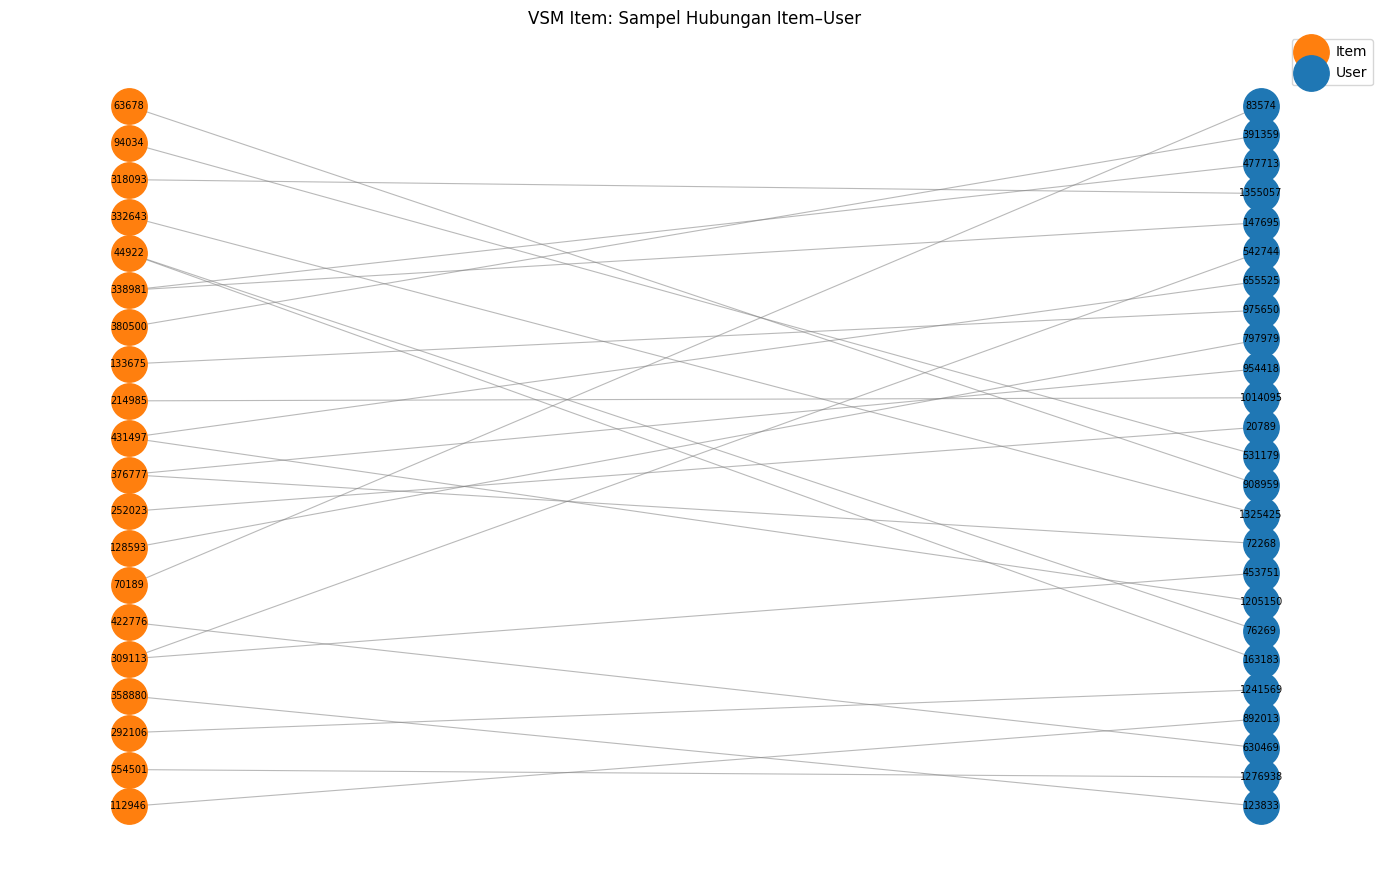

Jumlah simpul sampel: 45
Jumlah Item: 20
Jumlah Visitor: 25
Jumlah relasi sampel: 25


In [13]:
jumlah_visitor_per_item = np.diff(vsm_item.indptr)

kandidat_item = np.where(
    (jumlah_visitor_per_item >= 2) &
    (jumlah_visitor_per_item <= 6)
)[0]

rng = np.random.default_rng(42)

jumlah_item_plot = min(30, len(kandidat_item))
pilihan_item = rng.choice(
    kandidat_item,
    size=jumlah_item_plot,
    replace=False
)

kolom_visitor = set()
for idx in pilihan_item:
    kolom_visitor.update(vsm_item[idx].indices.tolist())

kolom_visitor = list(kolom_visitor)

frekuensi_visitor = np.asarray(
    vsm_item[pilihan_item, :][:, kolom_visitor].getnnz(axis=0)
).ravel()

urutan_visitor = np.argsort(frekuensi_visitor)[::-1][:25]
pilihan_visitor_item = [
    kolom_visitor[i] for i in urutan_visitor
]

G_item = nx.Graph()

for idx in pilihan_item:
    G_item.add_node(
        f"I{item_ids[idx]}",
        jenis="Item"
    )

for idx in pilihan_visitor_item:
    G_item.add_node(
        f"V{visitor_ids[idx]}",
        jenis="Visitor"
    )

for ii in pilihan_item:
    for vi in pilihan_visitor_item:
        nilai = vsm_item[ii, vi]
        if nilai > 0:
            G_item.add_edge(
                f"I{item_ids[ii]}",
                f"V{visitor_ids[vi]}",
                weight=int(nilai)
            )

G_item.remove_nodes_from(list(nx.isolates(G_item)))

item_nodes = [
    n for n, d in G_item.nodes(data=True)
    if d["jenis"] == "Item"
]

visitor_nodes = [
    n for n, d in G_item.nodes(data=True)
    if d["jenis"] == "Visitor"
]

pos = nx.bipartite_layout(
    G_item,
    item_nodes,
    align="vertical"
)

plt.figure(figsize=(14, 9))

nx.draw_networkx_edges(
    G_item, pos,
    edge_color="gray",
    alpha=0.55,
    width=0.8
)

nx.draw_networkx_nodes(
    G_item, pos,
    nodelist=item_nodes,
    node_color="tab:orange",
    node_size=650,
    label="Item"
)

nx.draw_networkx_nodes(
    G_item, pos,
    nodelist=visitor_nodes,
    node_color="tab:blue",
    node_size=650,
    label="User"
)

nx.draw_networkx_labels(
    G_item, pos,
    labels={n: n[1:] for n in G_item.nodes()},
    font_size=7
)

plt.title("VSM Item: Sampel Hubungan Item–User")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

print("Jumlah simpul sampel:", G_item.number_of_nodes())
print("Jumlah Item:", len(item_nodes))
print("Jumlah Visitor:", len(visitor_nodes))
print("Jumlah relasi sampel:", G_item.number_of_edges())


**Interpretasi Visualisasi VSM Item**

Visualisasi VSM Item ditampilkan dalam bentuk graf bipartit yang terdiri atas simpul Item berwarna oranye dan simpul Visitor berwarna biru. Garis yang menghubungkan kedua jenis simpul menunjukkan adanya interaksi antara Item dan Visitor pada data training P1.

Berdasarkan hasil visualisasi, graf sampel terdiri atas 45 simpul, yaitu 20 simpul Item dan 25 simpul Visitor, serta 25 relasi. Tidak semua Item yang dipilih pada tahap sampling muncul dalam graf akhir karena simpul yang tidak memiliki relasi dihapus dari visualisasi. Hal ini menunjukkan bahwa setiap Item hanya berinteraksi dengan Visitor tertentu.

Visualisasi ini hanya menampilkan sampel hubungan agar struktur graf lebih mudah diamati. Sementara itu, matriks VSM Item secara keseluruhan memiliki shape (207.371, 1.055.676) dengan 1.612.019 elemen non-zero.


### **Nomor 6:**
**Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)**

***Perbandingan VSM User dan VSM Item***

Berdasarkan hasil eksplorasi, VSM User memiliki shape (1.055.676, 207.371), sedangkan VSM Item memiliki shape (207.371, 1.055.676). Kedua matriks merepresentasikan interaksi yang sama pada data training P1, dengan orientasi baris dan kolom yang berbeda. VSM User menempatkan Visitor sebagai baris dan Item sebagai kolom, sedangkan VSM Item menempatkan Item sebagai baris dan Visitor sebagai kolom.

Kedua matriks memiliki 1.612.019 elemen non-zero dan menggunakan format sparse CSR (csr_matrix), sehingga keduanya menyimpan informasi interaksi yang sama dengan penggunaan memori yang lebih efisien dibandingkan matriks padat.

Dari sisi tujuan analisis, VSM Item lebih sesuai untuk menghitung kemiripan antarproduk, karena setiap Item direpresentasikan sebagai vektor berdasarkan pola interaksinya dengan Visitor. Sebaliknya, VSM User lebih sesuai untuk menghitung kemiripan antar pengguna berdasarkan pola interaksi mereka dengan Item.

Dengan demikian, proyeksi yang lebih sesuai bergantung pada tujuan analisis. Untuk analisis kemiripan antarproduk yang akan dilakukan pada Nomor 7, VSM Item dipilih karena setiap barisnya merepresentasikan satu Item yang akan dibandingkan dengan Item lainnya.

### **Nomor 7:**
**Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python**

**Hitung Cosine Similarity untuk Satu Item**

Similarity antar-Item dihitung menggunakan cosine similarity pada matriks VSM Item. Setiap Item direpresentasikan sebagai vektor interaksi terhadap Visitor (user). Nilai cosine similarity mendekati 1 menunjukkan pola interaksi yang semakin mirip, sedangkan nilai mendekati 0 menunjukkan kemiripan yang rendah.

Untuk menghindari pembentukan matriks similarity dense berukuran sangat besar, perhitungan dilakukan untuk satu Item sebagai anchor terhadap seluruh Item lainnya.

**(a). Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi**

**Menghitung cosine similarity antar-Item menggunakan VSM Item**

Perhitungan dilakukan menggunakan fungsi cosine_similarity dari sklearn.metrics.pairwise. Anchor item dipilih berdasarkan jumlah Visitor berbeda yang berinteraksi dengannya pada data training P1.

Setelah anchor item ditentukan, cosine similarity dihitung terhadap seluruh baris pada VSM Item. Item acuan dikeluarkan dari hasil, kemudian kandidat dengan nilai similarity positif diurutkan dari yang tertinggi. Lima kandidat teratas dipilih sebagai Item yang paling mirip dengan anchor item.

Hasil perhitungan Python selanjutnya disusun dalam daftar top5_similarity, yang memuat ID anchor item, ID Item serupa, dan nilai cosine similarity.

In [ ]:
%pip install scikit-learn

In [14]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

jumlah_visitor_item = np.diff(vsm_item.indptr)
anchor_idx = int(np.argmax(jumlah_visitor_item))
anchor_item_id = int(item_ids[anchor_idx])

similarity_anchor = cosine_similarity(
    vsm_item[anchor_idx],
    vsm_item,
    dense_output=True
).ravel()

urutan = np.argsort(similarity_anchor)[::-1]
urutan = [
    idx for idx in urutan
    if idx != anchor_idx and similarity_anchor[idx] > 0
][:5]

top5_similarity = [
    {
        "anchor_item": anchor_item_id,
        "similar_item": int(item_ids[idx]),
        "similarity": float(similarity_anchor[idx])
    }
    for idx in urutan
]

print("Anchor Item:", anchor_item_id)
print("\nTop 5 Item dengan Similarity Tertinggi:")

for row in top5_similarity:
    print(
        f"Item {row['similar_item']} | "
        f"Similarity: {row['similarity']:.6f}"
    )

Anchor Item: 5411

Top 5 Item dengan Similarity Tertinggi:
Item 33030 | Similarity: 0.140784
Item 37807 | Similarity: 0.109646
Item 33956 | Similarity: 0.094792
Item 89143 | Similarity: 0.091818
Item 459936 | Similarity: 0.068784


Berdasarkan perhitungan pada VSM Item, diperoleh Item 5411 sebagai anchor item. Item 33030 memperoleh nilai cosine similarity tertinggi sebesar 0.140784 di antara lima kandidat tersebut. Hasil ini menunjukkan bahwa pola interaksi Item 33030 paling mirip dengan Item 5411 dibandingkan empat kandidat lainnya.

**Penyimpanan Hasil Similarity pada Neo4j**

Hasil perhitungan cosine similarity dari Python disimpan ke database Neo4j sebagai relasi berarah SIMILAR_TO dari anchor item menuju lima Item serupa. Setiap relasi menyimpan properti cosine_similarity, method, dan period.

Properti tersebut digunakan untuk menyimpan nilai kemiripan, metode perhitungan yang digunakan, dan periode data yang dianalisis. Dengan demikian, hasil similarity dapat diakses kembali melalui query Cypher.


In [61]:
def simpan_similarity(tx, records):
    tx.run("""
        UNWIND $rows AS row
        MATCH (a:Item {itemid: row.anchor_item})
        MATCH (b:Item {itemid: row.similar_item})
        MERGE (a)-[r:SIMILAR_TO]->(b)
        SET r.cosine_similarity = row.similarity,
            r.method = 'cosine',
            r.period = 'P1'
    """, rows=records)

with driver.session(database="neo4j") as session:
    session.execute_write(
        simpan_similarity,
        top5_similarity
    )

print("Lima hasil similarity berhasil disimpan ke Neo4j.")


Lima hasil similarity berhasil disimpan ke Neo4j.


**Verifikasi Hasil dengan Query Cypher**

Query Cypher digunakan untuk mengambil relasi SIMILAR_TO dari Item 5411 yang dihitung menggunakan metode cosine pada periode P1. Hasil diurutkan berdasarkan nilai cosine_similarity secara menurun dan dibatasi hingga lima record.

In [62]:
with driver.session(database="neo4j") as session:
    hasil = session.run("""
        MATCH (a:Item {itemid: $anchor_id})-[r:SIMILAR_TO]->(b:Item)
        WHERE r.method = 'cosine'
          AND r.period = 'P1'
        RETURN
            a.itemid AS anchor_item,
            b.itemid AS similar_item,
            r.cosine_similarity AS similarity
        ORDER BY similarity DESC
        LIMIT 5
    """, anchor_id=anchor_item_id)

    for record in hasil:
        print(
            f"Anchor: {record['anchor_item']} | "
            f"Item serupa: {record['similar_item']} | "
            f"Similarity: {record['similarity']:.6f}"
        )


Anchor: 5411 | Item serupa: 33030 | Similarity: 0.140784
Anchor: 5411 | Item serupa: 37807 | Similarity: 0.109646
Anchor: 5411 | Item serupa: 33956 | Similarity: 0.094792
Anchor: 5411 | Item serupa: 89143 | Similarity: 0.091818
Anchor: 5411 | Item serupa: 459936 | Similarity: 0.068784


**Hasil Top 5 Similarity**

Berdasarkan perhitungan cosine similarity pada VSM Item, Item 5411 dipilih sebagai anchor berdasarkan jumlah Visitor unik terbanyak pada data training P1. Lima Item dengan nilai similarity tertinggi adalah Item 33030 (0.140784), Item 37807 (0.109646), Item 33956 (0.094792), Item 89143 (0.091818), dan Item 459936 (0.068784).

Hasil perhitungan Python kemudian disimpan ke Neo4j sebagai relasi SIMILAR_TO dengan properti cosine_similarity. Query Cypher berhasil menampilkan kembali lima pasangan tersebut beserta nilai similarity-nya.

**(b). Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil query-nya!**

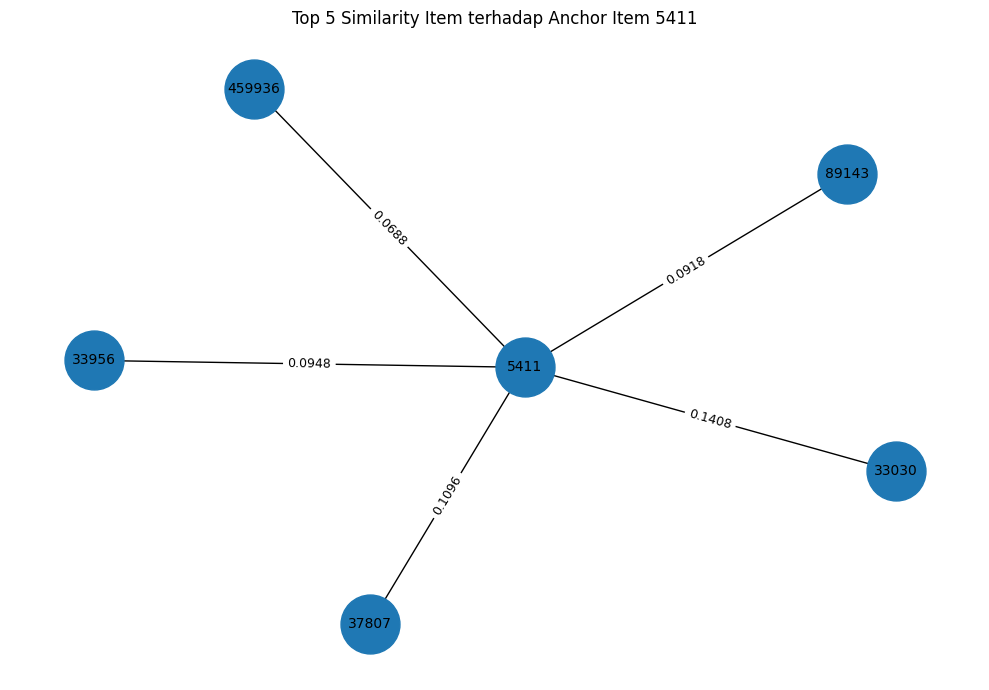

In [63]:
with driver.session(database="neo4j") as session:
    hasil = session.run("""
        MATCH (a:Item {itemid: 5411})-[r:SIMILAR_TO]->(b:Item)
        WHERE r.method = 'cosine'
          AND r.period = 'P1'
        RETURN
            a.itemid AS anchor_item,
            b.itemid AS similar_item,
            r.cosine_similarity AS similarity
        ORDER BY similarity DESC
        LIMIT 5
    """)

    records_similarity = [dict(record) for record in hasil]

G_similarity = nx.DiGraph()

for row in records_similarity:
    anchor = str(row["anchor_item"])
    similar = str(row["similar_item"])
    similarity = row["similarity"]

    G_similarity.add_edge(
        anchor,
        similar,
        weight=similarity
    )

pos = nx.spring_layout(G_similarity, seed=42)

plt.figure(figsize=(10, 7))

nx.draw_networkx_nodes(
    G_similarity,
    pos,
    node_size=1800
)

nx.draw_networkx_labels(
    G_similarity,
    pos,
    font_size=10
)

nx.draw_networkx_edges(
    G_similarity,
    pos,
    arrows=True,
    arrowsize=20
)

edge_labels = {
    (u, v): f"{data['weight']:.4f}"
    for u, v, data in G_similarity.edges(data=True)
}

nx.draw_networkx_edge_labels(
    G_similarity,
    pos,
    edge_labels=edge_labels,
    font_size=9
)

plt.title("Top 5 Similarity Item terhadap Anchor Item 5411")
plt.axis("off")
plt.tight_layout()
plt.show()



**Interpretasi Visualisasi Similarity**

Graf menunjukkan hubungan similarity antara anchor Item 5411 dan lima Item dengan nilai cosine similarity tertinggi. Nilai similarity ditampilkan pada setiap relasi SIMILAR_TO, sehingga tingkat kemiripan setiap pasangan dapat dibandingkan secara langsung.

Item 33030 memiliki nilai similarity tertinggi sebesar 0.140784, diikuti Item 37807 sebesar 0.109646, Item 33956 sebesar 0.094792, Item 89143 sebesar 0.091818, dan Item 459936 sebesar 0.068784. Hasil ini menunjukkan bahwa Item 33030 memiliki pola interaksi Visitor yang paling mirip dengan Item 5411 di antara lima kandidat tersebut.


### **Nomor 8:**
**Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity!**

**Graf Sebelum Perhitungan Similarity**

Graf menampilkan interaksi asli antara Visitor (User) dan Item 5411 pada periode training P1, yaitu 3 Mei hingga 10 Agustus 2015. Query Cypher digunakan untuk mengambil relasi VIEWED, ADDED_TO_CART, dan BOUGHT yang menghubungkan Visitor dengan Item tersebut.

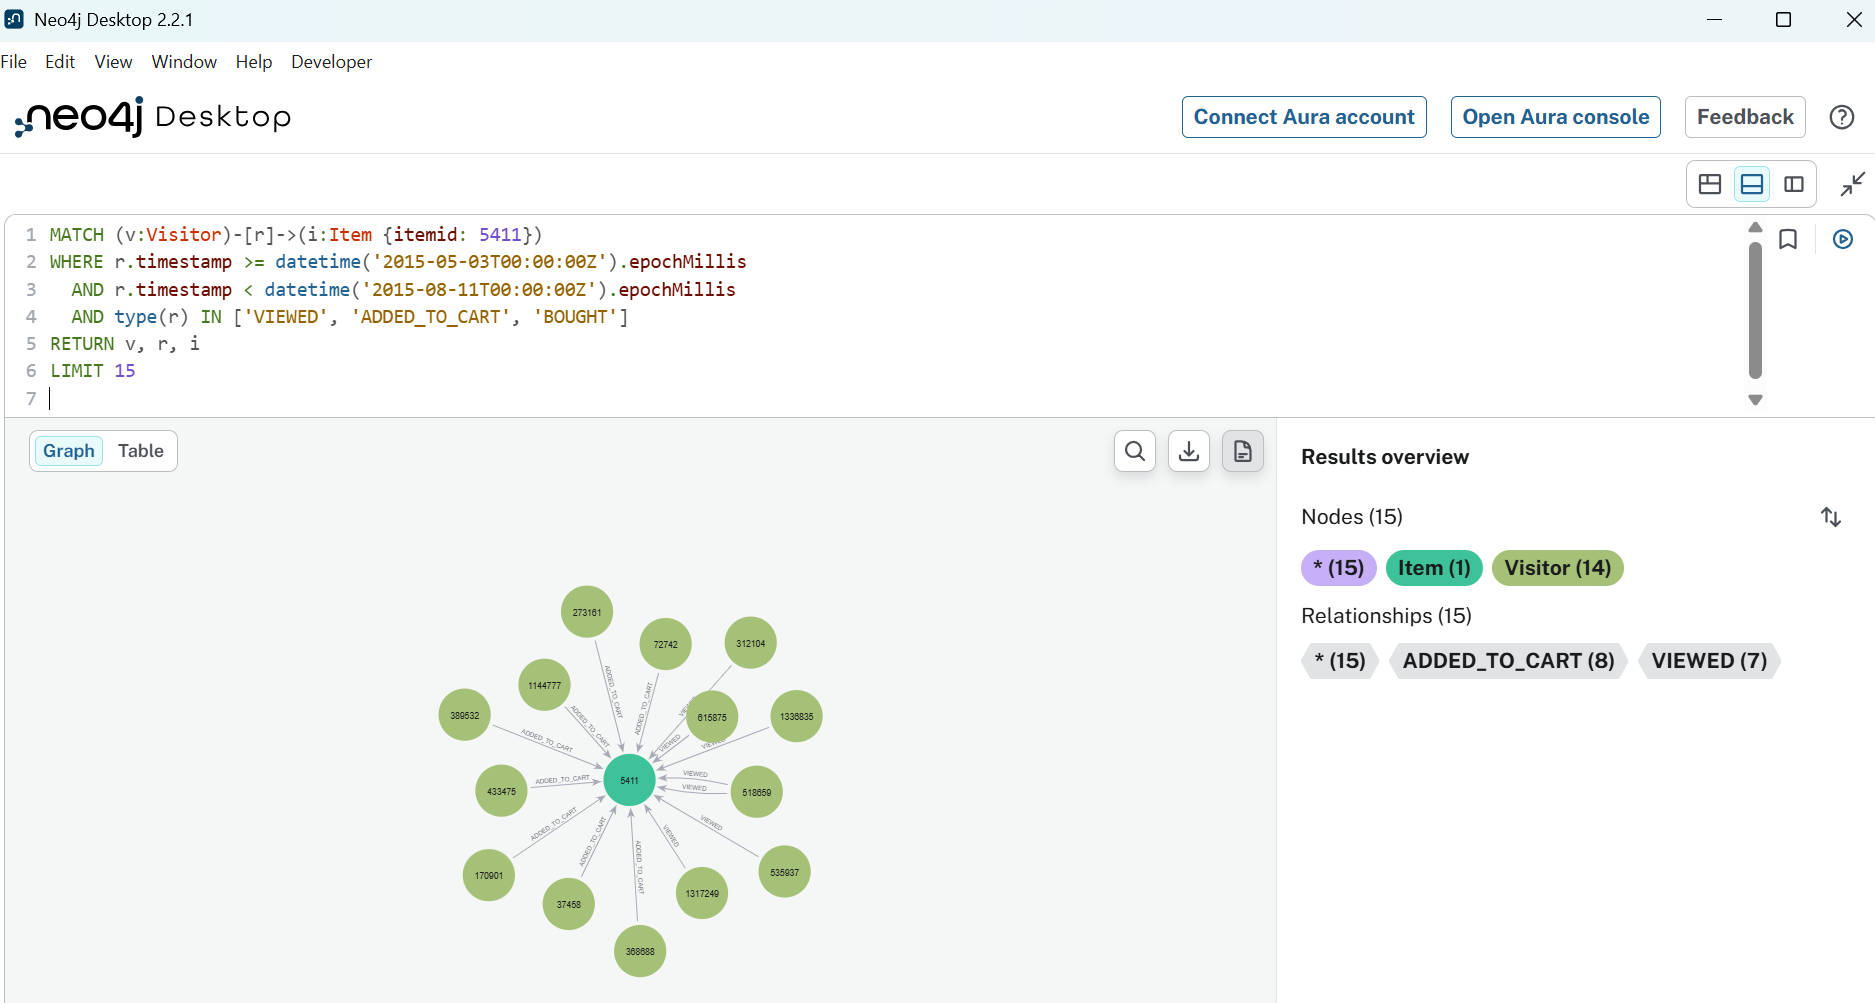

**Interpretasi**

Berdasarkan hasil visualisasi Neo4j, graf menampilkan 1 node Item, 14 node Visitor, dan 15 relasi interaksi. Relasi yang terlihat terdiri atas 8 relasi ADDED_TO_CART dan 7 relasi VIEWED. Graf ini menggambarkan interaksi asli antara Visitor dan Item 5411 yang tercatat dalam dataset pada periode P1.

**Sesudah Perhitungan Similarity**

Setelah perhitungan cosine similarity dilakukan menggunakan Python pada Nomor 7, hasil similarity disimpan ke Neo4j sebagai relasi SIMILAR_TO. Query berikut digunakan untuk menampilkan Item 5411 dan lima Item yang memiliki nilai similarity tertinggi pada periode P1.

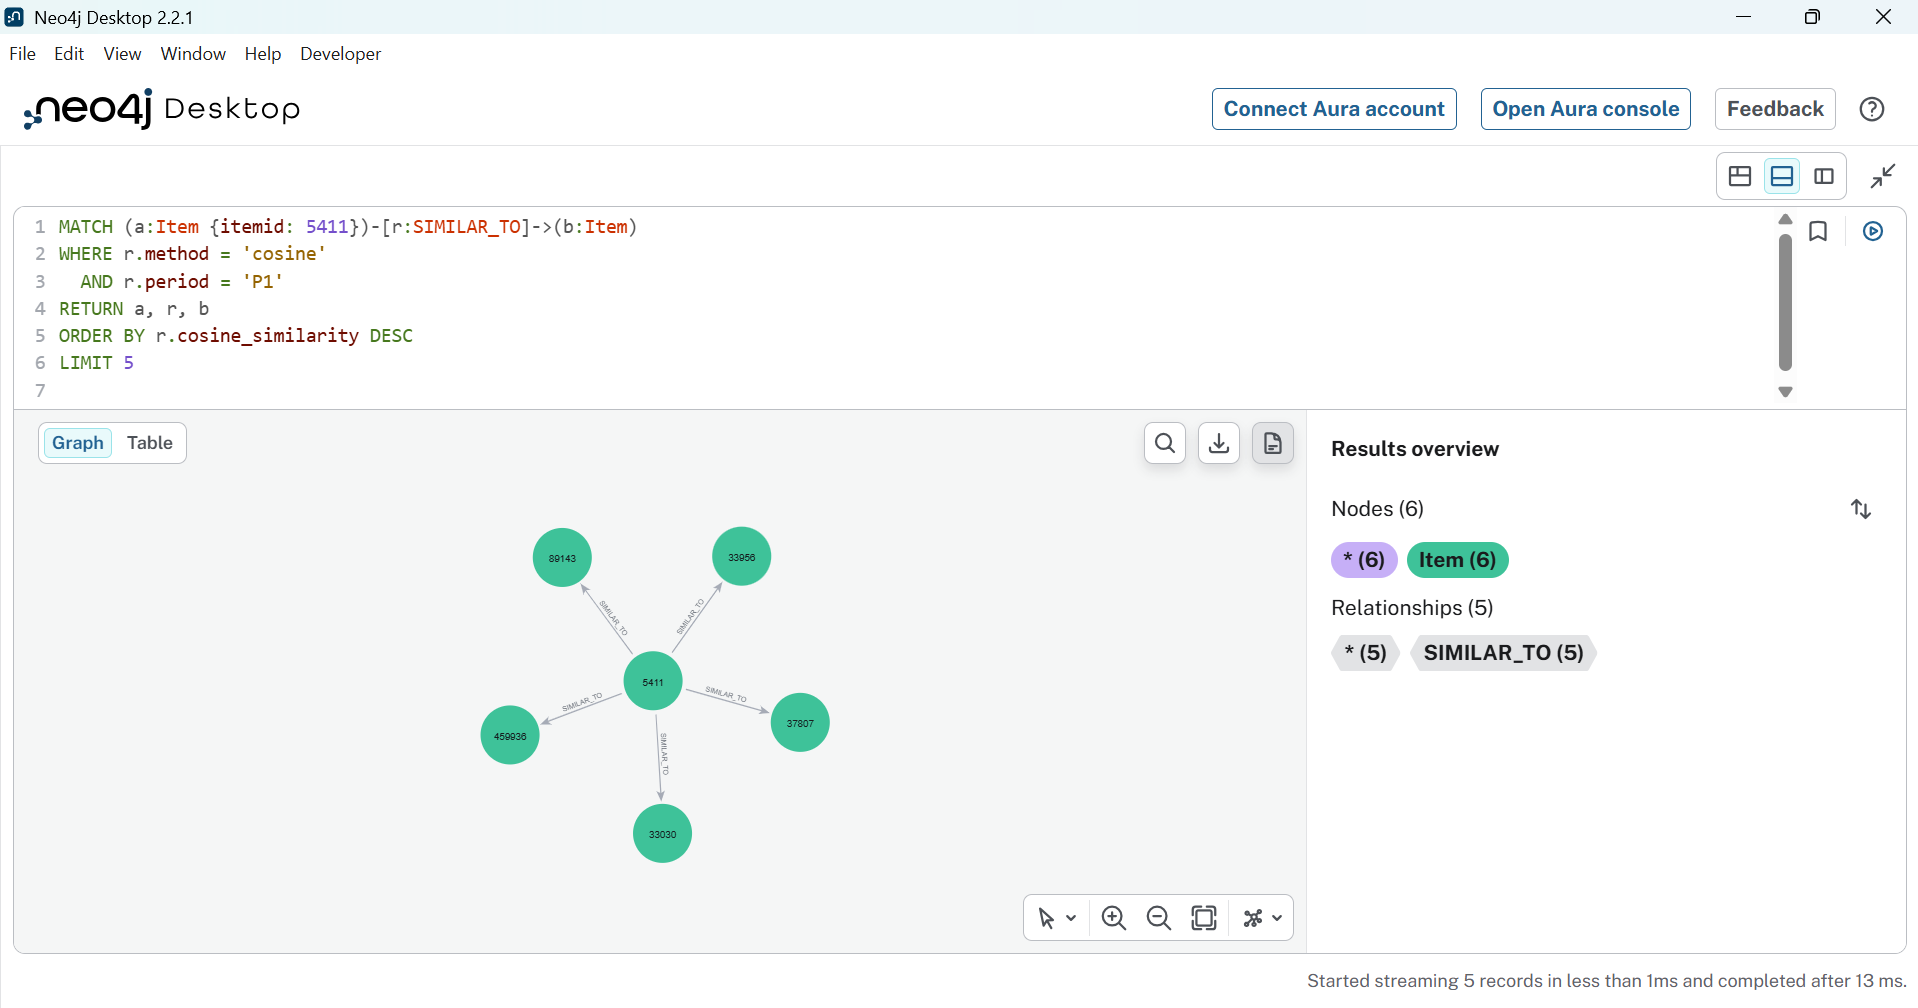

**Interpretasi**

Hasil visualisasi menampilkan 6 node Item dan 5 relasi SIMILAR_TO. Item 5411 berperan sebagai item acuan (anchor item) yang terhubung dengan lima Item serupa, yaitu Item 33030, 37807, 33956, 89143, dan 459936. Setiap relasi menyimpan nilai cosine similarity yang menunjukkan tingkat kemiripan pola interaksi antara Item acuan dan Item serupa.

**Perbandingan Sebelum dan Sesudah**

Sebelum perhitungan similarity, graf merepresentasikan interaksi antara Visitor dan Item 5411. Setelah perhitungan similarity, graf menampilkan hubungan kemiripan antar-Item berdasarkan pola interaksi Visitor pada data training P1. Dengan demikian, perhitungan similarity menambahkan informasi hubungan antarproduk yang dapat dimanfaatkan sebagai dasar pengembangan sistem rekomendasi.

## **2.2 Analytics**

### **Nomor 1:**

**Pilih seorang user secara acak (tentukan proses acaknya, dan harus bisa di-reproduksi)**

**(a). Tuliskan skrip Python dalam merekomendasikan KNN-nya**

Satu user dipilih secara acak menggunakan proses yang dapat direproduksi dengan random seed 42. Pemilihan dilakukan dari user yang memiliki interaksi pada periode training P1 dan testing P2. Selanjutnya, pendekatan K-Nearest Neighbors (KNN) digunakan untuk mencari lima user yang memiliki pola interaksi paling mirip dengan user target berdasarkan cosine similarity pada matriks VSM User.

In [28]:
import pandas as pd
import numpy as np

training = pd.read_csv("data/periode/P1_training.csv")
testing = pd.read_csv("data/periode/P2_testing.csv")

user_training = set(training["visitorid"].unique())
user_testing = set(testing["visitorid"].unique())

kandidat_user = np.array(
    sorted(user_training.intersection(user_testing))
)

rng = np.random.default_rng(42)
user_target = int(rng.choice(kandidat_user))

print("Jumlah kandidat user:", len(kandidat_user))
print("User target:", user_target)

Jumlah kandidat user: 27272
User target: 123715


Dari 27.272 kandidat user yang memiliki interaksi pada periode training P1 dan testing P2, terpilih User 123715 sebagai user target. User ini memenuhi kriteria karena memiliki interaksi pada kedua periode, sehingga pola interaksi pada data training dapat digunakan untuk menghasilkan rekomendasi dan hasilnya dapat dievaluasi menggunakan data testing.

**KNN dan tiga rekomendasi**

In [29]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

target_idx = visitor_ids.get_loc(user_target)

similarity_user = cosine_similarity(
    vsm_user[target_idx],
    vsm_user,
    dense_output=True
).ravel()

similarity_user[target_idx] = -1

neighbor_indices = np.argsort(similarity_user)[::-1][:5]

print("User target:", user_target)
print("\n5 tetangga terdekat:")

for idx in neighbor_indices:
    print(
        f"User {visitor_ids[idx]} | "
        f"Similarity: {similarity_user[idx]:.6f}"
    )

neighbor_matrix = vsm_user[neighbor_indices]
neighbor_weights = similarity_user[neighbor_indices]

skor_item = np.asarray(
    neighbor_matrix.T.dot(neighbor_weights)
).ravel()

item_sudah_dilihat = set(
    vsm_user[target_idx].indices.tolist()
)
skor_item[list(item_sudah_dilihat)] = -1

urutan_rekomendasi = np.argsort(skor_item)[::-1]
urutan_rekomendasi = [
    idx for idx in urutan_rekomendasi
    if skor_item[idx] >= 0
][:3]

item_rekomendasi = [
    int(item_ids[idx]) for idx in urutan_rekomendasi
]

print("\n3 rekomendasi Item untuk user", user_target, ":")

for idx in urutan_rekomendasi:
    print(
        f"Item {int(item_ids[idx])} | "
        f"Skor: {skor_item[idx]:.6f}"
    )

User target: 123715

5 tetangga terdekat:
User 74844 | Similarity: 0.872872
User 346851 | Similarity: 0.816497
User 940223 | Similarity: 0.816497
User 415128 | Similarity: 0.774597
User 856478 | Similarity: 0.696311

3 rekomendasi Item untuk user 123715 :
Item 99895 | Skor: 0.872872
Item 293363 | Skor: 0.696311
Item 187722 | Skor: 0.000000


**Hasil KNN**

Berdasarkan hasil perhitungan cosine similarity pada matriks VSM User, lima tetangga terdekat User 123715 adalah User 74844, 346851, 940223, 415128, dan 856478. Nilai cosine similarity tertinggi diperoleh User 74844 sebesar 0,872872, yang menunjukkan kemiripan pola interaksi paling tinggi terhadap user target di antara kelima tetangga tersebut.

Berdasarkan interaksi kelima tetangga dengan pembobotan cosine similarity, diperoleh tiga kandidat rekomendasi, yaitu Item 99895 dengan skor 0,872872, Item 293363 dengan skor 0,696311, dan Item 187722 dengan skor 0.

Item 99895 dan Item 293363 memperoleh skor positif dari interaksi kelima tetangga setelah dibobot dengan nilai cosine similarity. Sementara itu, Item 187722 memiliki skor nol, yang berarti tidak memperoleh kontribusi skor positif dari interaksi kelima tetangga berdasarkan perhitungan yang digunakan.

Item 187722 tetap masuk dalam daftar karena kode mengurutkan skor item dari tertinggi ke terendah, menyaring item dengan skor lebih besar atau sama dengan nol, kemudian mengambil maksimal tiga item pertama. Dengan demikian, jika jumlah item yang memiliki skor positif belum mencukupi, item berskor nol masih dapat terpilih untuk memenuhi jumlah rekomendasi yang diminta. Pemilihan ini merupakan konsekuensi dari mekanisme pemeringkatan dalam kode, bukan bukti bahwa Item 187722 memiliki dukungan preferensi dari kelima tetangga.

Dengan demikian, model menghasilkan tiga rekomendasi untuk User 123715 sesuai jumlah yang diminta. Namun, dua item pertama memiliki dukungan skor positif, sedangkan Item 187722 memiliki skor nol sehingga dukungan rekomendasinya lebih lemah.

### **Nomor 2:**

**Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah**

**(a). Hit@5**

Hit@5 digunakan untuk mengukur apakah setidaknya terdapat satu Item yang relevan di antara lima posisi teratas dalam daftar rekomendasi. Dalam penelitian ini, Item dianggap relevan apabila Item tersebut muncul dalam data interaksi user pada periode testing P2.

Metrik ini digunakan untuk mengetahui apakah sistem rekomendasi berhasil menemukan setidaknya satu Item yang benar-benar berinteraksi dengan user pada periode testing. Nilai Hit@5 adalah 1 jika minimal satu Item rekomendasi termasuk dalam daftar Item relevan, dan 0 jika tidak ada Item rekomendasi yang relevan.

In [30]:
item_relevan = set(
    testing.loc[
        testing["visitorid"] == user_target,
        "itemid"
    ].astype(int).unique()
)

rekomendasi = [int(item) for item in item_rekomendasi]

hit_at_5 = int(
    any(item in item_relevan for item in rekomendasi[:5])
)

print("User target:", user_target)
print("Item relevan di testing:", sorted(item_relevan))
print("Item rekomendasi:", rekomendasi)
print("Hit@5:", hit_at_5)

User target: 123715
Item relevan di testing: [np.int64(117075)]
Item rekomendasi: [99895, 293363, 187722]
Hit@5: 0


**Interpretasi Hit@5**

Berdasarkan data testing P2, User 123715 memiliki satu Item relevan, yaitu Item 117075. Sementara itu, tiga Item yang direkomendasikan oleh model adalah Item 99895, 293363, dan 187722. Tidak ada Item rekomendasi yang cocok dengan Item relevan pada data testing. Oleh karena itu, nilai Hit@5 adalah 0.

Hasil ini menunjukkan bahwa model belum berhasil menemukan Item yang berinteraksi dengan user target selama periode testing P2 dalam daftar rekomendasinya. Nilai tersebut hanya menggambarkan kinerja model pada user yang dipilih, bukan kinerja model untuk seluruh user.

**(b). NDCG@5**

Normalized Discounted Cumulative Gain (NDCG@5) digunakan untuk mengevaluasi kualitas daftar rekomendasi dengan mempertimbangkan relevansi Item dan posisi Item tersebut dalam daftar rekomendasi. Item relevan yang muncul pada posisi lebih tinggi akan memberikan kontribusi nilai yang lebih besar dibandingkan Item relevan pada posisi lebih rendah.

Metrik ini digunakan untuk mengetahui seberapa baik urutan rekomendasi yang dihasilkan model dibandingkan dengan urutan rekomendasi ideal. Nilai NDCG@5 berada pada rentang 0 hingga 1. Nilai yang semakin mendekati 1 menunjukkan bahwa urutan rekomendasi semakin baik berdasarkan relevansi Item.

Perhitungan dilakukan melalui tiga tahap:

1. DCG@5 (Discounted Cumulative Gain): menghitung nilai relevansi rekomendasi dengan memberikan bobot berdasarkan posisi Item.

2. IDCG@5 (Ideal Discounted Cumulative Gain): menghitung nilai DCG ideal jika Item relevan ditempatkan pada posisi terbaik.

3. NDCG@5: membagi DCG@5 dengan IDCG@5 untuk memperoleh nilai evaluasi yang telah dinormalisasi.

In [31]:
import numpy as np

rekomendasi = [int(item) for item in item_rekomendasi]

relevansi = [
    1 if item in item_relevan else 0
    for item in rekomendasi[:5]
]

# DCG@5
dcg_at_5 = sum(
    rel / np.log2(posisi + 2)
    for posisi, rel in enumerate(relevansi)
)

# IDCG@5 berdasarkan jumlah Item relevan
jumlah_relevan_ideal = min(len(item_relevan), 5)

idcg_at_5 = sum(
    1 / np.log2(posisi + 2)
    for posisi in range(jumlah_relevan_ideal)
)

# NDCG@5
ndcg_at_5 = (
    dcg_at_5 / idcg_at_5
    if idcg_at_5 > 0
    else 0.0
)

print("User target:", user_target)
print("Item relevan:", sorted(item_relevan))
print("Item rekomendasi:", rekomendasi)
print("Relevansi rekomendasi:", relevansi)
print(f"DCG@5: {dcg_at_5:.6f}")
print(f"IDCG@5: {idcg_at_5:.6f}")
print(f"NDCG@5: {ndcg_at_5:.6f}")

User target: 123715
Item relevan: [np.int64(117075)]
Item rekomendasi: [99895, 293363, 187722]
Relevansi rekomendasi: [0, 0, 0]
DCG@5: 0.000000
IDCG@5: 1.000000
NDCG@5: 0.000000


**Interpretasi NDCG@5**

Berdasarkan hasil evaluasi, relevansi ketiga Item rekomendasi adalah [0, 0, 0] karena tidak ada Item rekomendasi yang cocok dengan Item relevan pada data testing P2. Akibatnya, nilai DCG@5 adalah 0. Sementara itu, IDCG@5 sebesar 1 karena terdapat satu Item relevan yang dapat menempati peringkat pertama dalam urutan ideal.

Perbandingan DCG@5 dengan IDCG@5 menghasilkan NDCG@5 sebesar 0. Artinya, daftar rekomendasi belum berhasil menempatkan Item relevan pada posisi mana pun. Hasil ini konsisten dengan nilai Hit@5 yang juga sebesar 0.